# Techniques de split dans les arbres de décision
## Classification vs Régression (Pour aller plus loin)

> **Prérequis** : vous savez déjà ce qu'est un arbre de décision (racine, nœud interne, feuille, branche) et vous avez déjà croisé la notion d'entropie. Ce notebook creuse **comment un arbre choisit concrètement chaque question (split)**, et montre que classification et régression n'utilisent pas les mêmes critères.

Quel que soit le problème (classification ou régression), un arbre choisit toujours le split qui fait le plus **baisser l'impureté / la dispersion** entre le nœud parent et ses enfants. Ce qui change, c'est **la façon de mesurer cette impureté**  et ce choix a des conséquences pratiques importantes (biais, robustesse, coût de calcul).

### Objectifs de ce notebook

- Formaliser le critère général de sélection d'un split.
- **Classification** : entropie, indice de Gini, gain ratio (biais de cardinalité), distance de Hellinger (classes déséquilibrées).
- **Régression** : réduction de variance (MSE), MAE, Friedman MSE, déviance de Poisson.
- Comparer ces critères sur des cas concrets (données déséquilibrées, valeurs aberrantes, variables à forte cardinalité).
- Repartir avec un tableau récapitulatif et des pistes pour aller encore plus loin.

### Sommaire

1. [Le critère général de split](#critere-general)
2. [Classification : mesurer le mélange des classes](#classification)
   - 2.1 Entropie, Gini, erreur de classification
   - 2.2 Le biais des variables à forte cardinalité et le *gain ratio*
   - 2.3 Classes déséquilibrées : la distance de Hellinger
3. [Régression : mesurer la dispersion d'une valeur continue](#regression)
   - 3.1 Réduction de variance (MSE)
   - 3.2 MAE : robustesse aux valeurs aberrantes
   - 3.3 Friedman MSE
   - 3.4 Déviance de Poisson (données de comptage)
4. [Tableau récapitulatif](#recap)
5. [Pour aller plus loin](#plus-loin)


<a name="critere-general"></a>
## 1. Le critère général de split

Pour un nœud parent $P$ séparé en deux enfants $G$ (gauche) et $D$ (droite) par une question, on définit un score de qualité du split :

$$
\Delta I = I(P) \;-\; \left( \frac{n_G}{n_P} I(G) + \frac{n_D}{n_P} I(D) \right)
$$

où $I(\cdot)$ est une **mesure d'impureté** (classification) ou de **dispersion** (régression), et $n_G, n_D, n_P$ sont les effectifs de chaque nœud.

L'algorithme teste, pour chaque variable et chaque seuil possible, la valeur de $\Delta I$, et retient le split qui la maximise. Tout l'enjeu de ce notebook est de comprendre **ce qu'on met derrière $I(\cdot)$**, et pourquoi ce choix n'est pas neutre.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_regression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

np.random.seed(42)
plt.rcParams["figure.dpi"] = 110


<a name="classification"></a>
## 2. Classification : mesurer le mélange des classes

### 2.1 Entropie, Gini, erreur de classification

Pour un nœud contenant des proportions $p_1, \dots, p_K$ de chaque classe :

| Critère | Formule | Utilisé par |
|---|---|---|
| Entropie | $H = -\sum_k p_k \log_2 p_k$ | ID3, C4.5 (`criterion='entropy'` / `'log_loss'`) |
| Gini | $G = 1 - \sum_k p_k^2$ | CART (`criterion='gini'`, défaut sklearn) |
| Erreur de classification | $E = 1 - \max_k p_k$ | rarement utilisé pour construire l'arbre (peu sensible aux petites variations) |

**Pourquoi Gini est le critère par défaut de scikit-learn ?** Il ne demande pas de calculer de logarithme (moins coûteux à grande échelle) et se comporte très proche de l'entropie en pratique. L'erreur de classification, elle, est trop "plate" autour de son optimum : elle ne distingue pas deux splits qui améliorent la pureté de façon différente si le vote majoritaire ne change pas, donc les algorithmes gloutons s'y perdent.


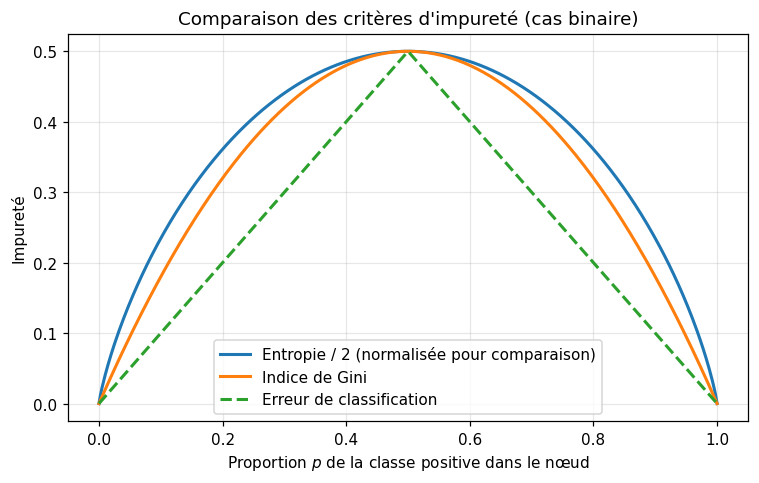

In [2]:
def entropy(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))

def gini(p):
    return 1 - (p**2 + (1 - p)**2)

def misclassification(p):
    return 1 - np.maximum(p, 1 - p)

p = np.linspace(0, 1, 400)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(p, entropy(p) / 2, label="Entropie / 2 (normalisée pour comparaison)", lw=2)
ax.plot(p, gini(p), label="Indice de Gini", lw=2)
ax.plot(p, misclassification(p), label="Erreur de classification", lw=2, linestyle="--")
ax.set_xlabel("Proportion $p$ de la classe positive dans le nœud")
ax.set_ylabel("Impureté")
ax.set_title("Comparaison des critères d'impureté (cas binaire)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Lecture du graphique** : les trois courbes sont maximales quand $p=0.5$ (mélange parfait) et nulles quand $p \in \{0, 1\}$ (nœud pur). Entropie et Gini sont **strictement concaves partout**, ce qui les rend sensibles aux petites améliorations même loin de l'optimum  contrairement à l'erreur de classification, plus "anguleuse", qui reste souvent identique pour deux splits différents.


### 2.2 Le biais des variables à forte cardinalité et le *gain ratio*

Le **gain d'information** brut, $GI = H(P) - \sum_c \frac{n_c}{n_P} H(c)$, a un défaut connu (Quinlan, 1986) : il **favorise artificiellement les variables qui ont beaucoup de modalités distinctes**, même si elles n'ont aucun pouvoir prédictif réel — un identifiant client en est l'exemple caricatural : en séparant sur l'ID, chaque feuille ne contient qu'une seule observation, donc l'entropie tombe à 0 partout, et le gain d'information est maximal !

**C4.5** corrige ce biais avec le **gain ratio** :

$$
GR = \frac{GI}{SplitInfo}, \qquad SplitInfo = -\sum_c \frac{n_c}{n_P} \log_2\left(\frac{n_c}{n_P}\right)
$$

Le $SplitInfo$ pénalise les variables qui créent beaucoup de petits groupes (il joue le même rôle qu'une entropie, mais sur la répartition des effectifs plutôt que sur les classes).


In [3]:
def information_gain(y, groups):
    n = len(y)
    parent_p = y.mean()
    h_parent = entropy(np.array([parent_p]))[0]
    weighted = sum(len(g) / n * entropy(np.array([g.mean()]))[0] for g in groups if len(g) > 0)
    return h_parent - weighted

def split_info(groups, n):
    props = np.array([len(g) / n for g in groups if len(g) > 0])
    return -np.sum(props * np.log2(props))

def gain_ratio(y, groups):
    gi = information_gain(y, groups)
    si = split_info(groups, len(y))
    return gi / si if si > 0 else 0.0

# Jeu de données jouet : un "ID client" quasi-unique (aucune valeur prédictive)
# et une vraie variable utile "a_deja_achete" (binaire, informative).
n_customers = 200
rng = np.random.default_rng(0)

customer_id = np.arange(n_customers)                     # cardinalité maximale : 200 valeurs distinctes
a_deja_achete = rng.integers(0, 2, n_customers)           # variable binaire, vraiment informative
target = (a_deja_achete + rng.normal(0, 0.35, n_customers) > 0.5).astype(int)

groups_id = [target[customer_id == cid] for cid in np.unique(customer_id)]
groups_binaire = [target[a_deja_achete == v] for v in [0, 1]]

gi_label = "Gain d'information"
print(f"{'Variable':<20}{gi_label:>20}{'Gain ratio':>15}")
print(f"{'customer_id':<20}{information_gain(target, groups_id):>20.3f}{gain_ratio(target, groups_id):>15.3f}")
print(f"{'a_deja_achete':<20}{information_gain(target, groups_binaire):>20.3f}{gain_ratio(target, groups_binaire):>15.3f}")


Variable              Gain d'information     Gain ratio
customer_id                        0.995          0.130
a_deja_achete                      0.612          0.617


On observe le piège : le **gain d'information brut classe `customer_id` en tête**, alors que cette variable ne généralise évidemment à rien (chaque client a une valeur unique). Le **gain ratio rééquilibre le classement** en tenant compte du nombre de groupes créés. C'est cette correction qui est utilisée dans C4.5, scikit-learn, lui, ne l'implémente pas nativement et s'appuie plutôt sur des mécanismes différents (limitation de `max_features`, pruning, `min_samples_leaf`) pour limiter ce biais.


### 2.3 Classes déséquilibrées : la distance de Hellinger

Sur un jeu de données très déséquilibré (fraude, défaut de paiement...), Gini et l'entropie ont tendance à choisir des splits qui optimisent la précision globale en "ignorant" la classe minoritaire, car celle-ci pèse peu dans le calcul des proportions.

La **distance de Hellinger** (Cieslak & Chawla, 2008) est un critère **invariant au déséquilibre des classes**. Elle compare directement la façon dont chaque branche capture la classe positive vs négative, sans être dominé par leurs effectifs respectifs :

$$
d_{\mathcal{H}}(G, D) = \sqrt{ \left(\sqrt{\frac{n_{G,+}}{n_+}} - \sqrt{\frac{n_{D,+}}{n_+}}\right)^2 + \left(\sqrt{\frac{n_{G,-}}{n_-}} - \sqrt{\frac{n_{D,-}}{n_-}}\right)^2 }
$$

où $n_+$ et $n_-$ sont les effectifs totaux de chaque classe (pas seulement dans le nœud courant).


Répartition des classes : [1889  111] (5.5% de positifs)


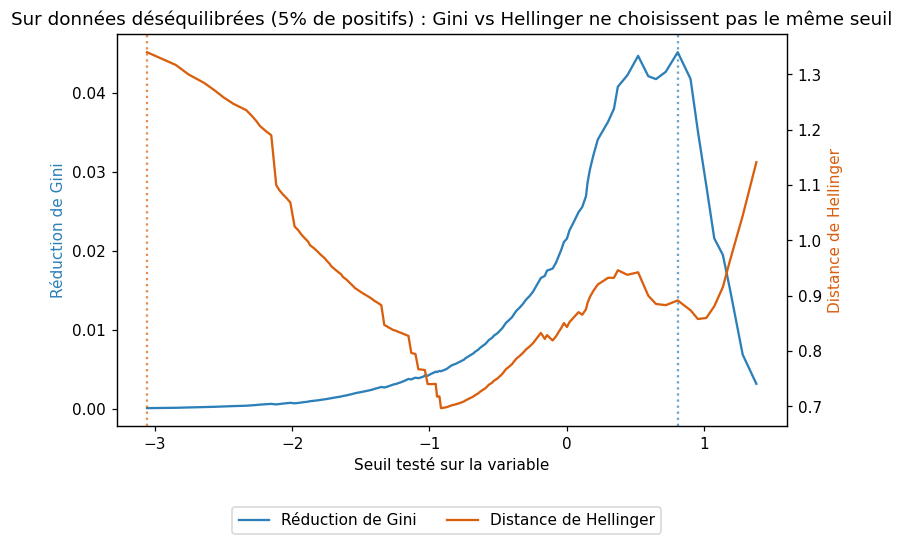

Meilleur seuil selon Gini      : 0.807
Meilleur seuil selon Hellinger : -3.056


In [4]:
from sklearn.datasets import make_classification

X, y = make_classification(
    n_samples=2000, n_features=2, n_redundant=0, n_informative=2,
    n_clusters_per_class=1, weights=[0.95, 0.05], flip_y=0.01, random_state=7
)
print("Répartition des classes :", np.bincount(y), f"({np.bincount(y)[1] / len(y):.1%} de positifs)")

def gini_score(y, mask):
    n = len(y)
    groups = [y[mask], y[~mask]]
    parent = gini(np.array([y.mean()]))[0]
    weighted = sum(len(g) / n * gini(np.array([g.mean()]))[0] for g in groups if len(g) > 0)
    return parent - weighted

def hellinger_score(y, mask):
    n_pos, n_neg = (y == 1).sum(), (y == 0).sum()
    g_pos, g_neg = ((y[mask] == 1).sum(), (y[mask] == 0).sum())
    d_pos, d_neg = ((y[~mask] == 1).sum(), (y[~mask] == 0).sum())
    term_pos = (np.sqrt(g_pos / n_pos) - np.sqrt(d_pos / n_pos)) ** 2
    term_neg = (np.sqrt(g_neg / n_neg) - np.sqrt(d_neg / n_neg)) ** 2
    return np.sqrt(term_pos + term_neg)

feature = X[:, 0]
thresholds = np.percentile(feature, np.linspace(1, 99, 150))

gini_scores = [gini_score(y, feature <= t) for t in thresholds]
hellinger_scores = [hellinger_score(y, feature <= t) for t in thresholds]

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax2 = ax.twinx()
ax.plot(thresholds, gini_scores, color="#2c7fb8", label="Réduction de Gini")
ax2.plot(thresholds, hellinger_scores, color="#d95f0e", label="Distance de Hellinger")
ax.axvline(thresholds[np.argmax(gini_scores)], color="#2c7fb8", linestyle=":", alpha=0.7)
ax2.axvline(thresholds[np.argmax(hellinger_scores)], color="#d95f0e", linestyle=":", alpha=0.7)
ax.set_xlabel("Seuil testé sur la variable")
ax.set_ylabel("Réduction de Gini", color="#2c7fb8")
ax2.set_ylabel("Distance de Hellinger", color="#d95f0e")
ax.set_title("Sur données déséquilibrées (5% de positifs) : Gini vs Hellinger ne choisissent pas le même seuil")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2)
plt.tight_layout()
plt.show()

print(f"Meilleur seuil selon Gini      : {thresholds[np.argmax(gini_scores)]:.3f}")
print(f"Meilleur seuil selon Hellinger : {thresholds[np.argmax(hellinger_scores)]:.3f}")


Le critère de Hellinger, ne dépendant pas des proportions globales de classes, reste stable même si vous rééchantillonnez le jeu de données pour changer son déséquilibre, une propriété que ni Gini ni l'entropie ne possèdent. Il n'est pas disponible nativement dans scikit-learn, mais des implémentations existent (ex. package `hddt`, ou approche manuelle avec un `DecisionTreeClassifier` personnalisé via un critère Cython).


<a name="regression"></a>
## 3. Régression : mesurer la dispersion d'une valeur continue

En régression, il n'y a plus de "classes" à démêler : l'impureté d'un nœud devient une mesure de **dispersion des valeurs cibles** autour de leur meilleure prédiction constante (la moyenne, en général).

### 3.1 Réduction de variance (MSE)

$$
I_{MSE}(\text{nœud}) = \frac{1}{n}\sum_{i \in \text{nœud}} (y_i - \bar{y})^2
$$

C'est le critère `squared_error` de scikit-learn (celui par défaut) : la prédiction d'une feuille est la moyenne de `y`, et le split retenu est celui qui réduit le plus la variance pondérée des enfants.


In [5]:
def mse_impurity(y):
    return np.mean((y - y.mean()) ** 2) if len(y) > 0 else 0.0

def mae_impurity(y):
    return np.mean(np.abs(y - np.median(y))) if len(y) > 0 else 0.0

def best_split_regression(x, y, criterion="mse"):
    impurity_fn = mse_impurity if criterion == "mse" else mae_impurity
    n = len(y)
    parent_imp = impurity_fn(y)
    thresholds = np.unique(x)
    best_gain, best_t = -np.inf, None
    for t in thresholds:
        left, right = y[x <= t], y[x > t]
        if len(left) == 0 or len(right) == 0:
            continue
        weighted = (len(left) / n) * impurity_fn(left) + (len(right) / n) * impurity_fn(right)
        gain = parent_imp - weighted
        if gain > best_gain:
            best_gain, best_t = gain, t
    return best_t, best_gain


### 3.2 MAE : robustesse aux valeurs aberrantes

$$
I_{MAE}(\text{nœud}) = \frac{1}{n}\sum_{i \in \text{nœud}} |y_i - \text{médiane}(y)|
$$

La variance (MSE) **élève les écarts au carré**, donc une seule valeur aberrante peut dominer tout le calcul et décaler le split choisi. La MAE, construite sur la médiane, est beaucoup plus robuste mais elle coûte plus cher à calculer (il faut trier / trouver la médiane à chaque seuil testé, alors que la moyenne se met à jour en $O(1)$).


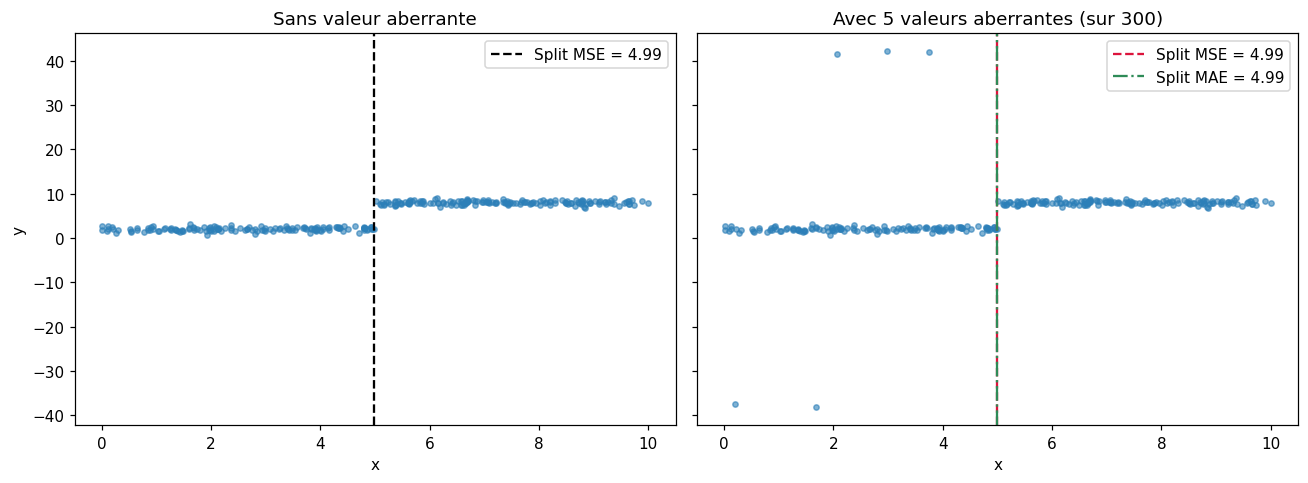

Split MSE (données propres)     : 4.988
Split MSE (avec valeurs aberr.)  : 4.988  <- décalé par les outliers
Split MAE (avec valeurs aberr.)  : 4.988  <- reste proche du vrai seuil (5.0)


In [6]:
rng = np.random.default_rng(3)
x = np.sort(rng.uniform(0, 10, 300))
y_clean = np.where(x < 5, 2.0, 8.0) + rng.normal(0, 0.4, 300)

# On injecte quelques valeurs aberrantes extrêmes du côté "x < 5"
y_outliers = y_clean.copy()
outlier_idx = rng.choice(np.where(x < 5)[0], size=5, replace=False)
y_outliers[outlier_idx] += rng.choice([40, -40], size=5)

t_mse_clean, _ = best_split_regression(x, y_clean, "mse")
t_mse_out, _ = best_split_regression(x, y_outliers, "mse")
t_mae_out, _ = best_split_regression(x, y_outliers, "mae")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
axes[0].scatter(x, y_clean, s=12, alpha=0.6, color="#2c7fb8")
axes[0].axvline(t_mse_clean, color="black", linestyle="--", label=f"Split MSE = {t_mse_clean:.2f}")
axes[0].set_title("Sans valeur aberrante")
axes[0].legend()

axes[1].scatter(x, y_outliers, s=12, alpha=0.6, color="#2c7fb8")
axes[1].axvline(t_mse_out, color="crimson", linestyle="--", label=f"Split MSE = {t_mse_out:.2f}")
axes[1].axvline(t_mae_out, color="seagreen", linestyle="-.", label=f"Split MAE = {t_mae_out:.2f}")
axes[1].set_title("Avec 5 valeurs aberrantes (sur 300)")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("x")
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

print(f"Split MSE (données propres)     : {t_mse_clean:.3f}")
print(f"Split MSE (avec valeurs aberr.)  : {t_mse_out:.3f}  <- décalé par les outliers")
print(f"Split MAE (avec valeurs aberr.)  : {t_mae_out:.3f}  <- reste proche du vrai seuil (5.0)")


Sur seulement 5 valeurs aberrantes parmi 300 observations, le split basé sur MSE peut déjà se décaler significativement, alors que le split basé sur MAE reste proche du vrai seuil (x = 5). C'est pour cette raison que scikit-learn propose `criterion='absolute_error'` dans `DecisionTreeRegressor` au prix d'un temps d'entraînement plus long.


### 3.3 Friedman MSE

Friedman (2001, *Greedy Function Approximation*) propose un score légèrement différent du simple gain de variance, pensé pour les cas où l'arbre sert de "weak learner" dans du **gradient boosting** :

$$
\text{Score}_{Friedman} = \frac{n_G \, n_D}{n_G + n_D} \, (\bar{y}_G - \bar{y}_D)^2
$$

Contrairement au gain MSE classique, ce score **ne nécessite pas de recalculer l'impureté du parent** (qui est constante d'un split à l'autre) et pondère différemment les tailles de groupes très déséquilibrées entre gauche et droite ce qui, empiriquement, donne de meilleures approximations lors d'étapes de boosting successives. C'est le critère par défaut de `GradientBoostingRegressor` (`criterion='friedman_mse'`), et il est aussi disponible pour `DecisionTreeRegressor` seul.


In [7]:
def friedman_score(y, left_mask):
    left, right = y[left_mask], y[~left_mask]
    n_g, n_d = len(left), len(right)
    if n_g == 0 or n_d == 0:
        return 0.0
    return (n_g * n_d) / (n_g + n_d) * (left.mean() - right.mean()) ** 2

def mse_gain(y, left_mask):
    left, right = y[left_mask], y[~left_mask]
    n = len(y)
    parent = mse_impurity(y)
    weighted = (len(left) / n) * mse_impurity(left) + (len(right) / n) * mse_impurity(right)
    return parent - weighted

# Comparaison sur quelques seuils candidats : les deux critères concordent-ils
# sur le MEILLEUR seuil, même s'ils n'ont pas la même échelle ?
thresholds = np.unique(x)[::5]
mse_gains = [mse_gain(y_outliers, x <= t) for t in thresholds]
friedman_gains = [friedman_score(y_outliers, x <= t) for t in thresholds]

print(f"Meilleur seuil (MSE gain)      : {thresholds[np.argmax(mse_gains)]:.3f}")
print(f"Meilleur seuil (Friedman MSE)  : {thresholds[np.argmax(friedman_gains)]:.3f}")
print("-> Sur un arbre isolé, les deux critères choisissent généralement le même split.")
print("   L'intérêt de Friedman MSE apparaît surtout en boosting, où il évalue mieux")
print("   l'apport d'un split par rapport au modèle déjà construit (pas juste par rapport à la moyenne locale).")


Meilleur seuil (MSE gain)      : 5.099
Meilleur seuil (Friedman MSE)  : 5.099
-> Sur un arbre isolé, les deux critères choisissent généralement le même split.
   L'intérêt de Friedman MSE apparaît surtout en boosting, où il évalue mieux
   l'apport d'un split par rapport au modèle déjà construit (pas juste par rapport à la moyenne locale).


### 3.4 Déviance de Poisson (données de comptage)

Quand la cible $y$ représente des **comptages ou des taux** (nombre de sinistres, de clics, de visites toujours $\geq 0$, souvent avec beaucoup de zéros), supposer une distribution gaussienne (MSE) n'est pas idéal : la variance d'un Poisson dépend de sa moyenne, et MSE peut prédire des valeurs négatives, impossibles pour un comptage.

Le critère **`poisson`** de scikit-learn utilise la déviance de Poisson comme impureté :

$$
I_{Poisson}(\text{nœud}) = \frac{2}{n}\sum_{i} \left( y_i \log\frac{y_i}{\bar{y}} - (y_i - \bar{y}) \right)
$$

Contrainte importante : ce critère nécessite $y \geq 0$ (et la moyenne des feuilles $> 0$), sinon `DecisionTreeRegressor(criterion='poisson')` renvoie une erreur.


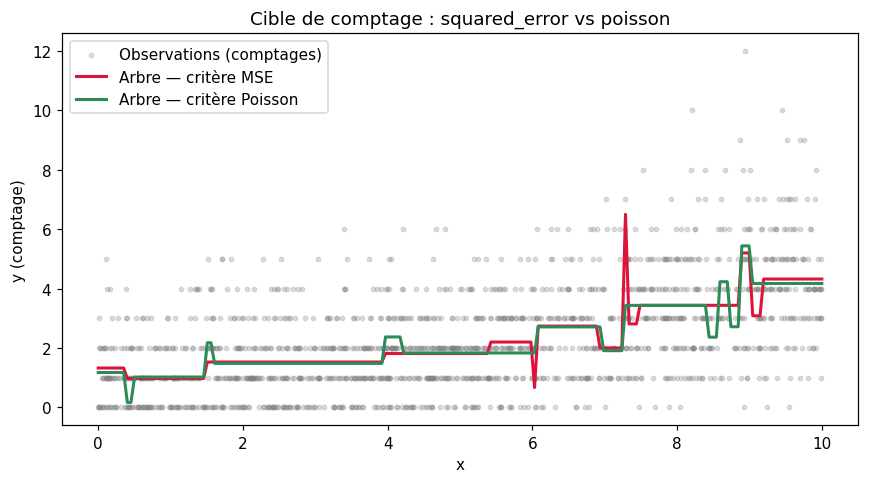

Déviance de Poisson (arbre MSE)      : 1.1299


Déviance de Poisson (arbre Poisson)  : 1.1720


In [8]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(5)
n = 1500
x_feat = rng.uniform(0, 10, n)
# Taux d'événements croissant avec x, données de comptage (Poisson)
lam = np.exp(0.15 * x_feat)
y_counts = rng.poisson(lam)

X_train, X_test, y_train, y_test = train_test_split(
    x_feat.reshape(-1, 1), y_counts, test_size=0.3, random_state=0
)

tree_mse = DecisionTreeRegressor(criterion="squared_error", max_depth=4, random_state=0).fit(X_train, y_train)
tree_poisson = DecisionTreeRegressor(criterion="poisson", max_depth=4, random_state=0).fit(X_train, y_train)

grid = np.linspace(0, 10, 200).reshape(-1, 1)
pred_mse = tree_mse.predict(grid)
pred_poisson = tree_poisson.predict(grid)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x_feat, y_counts, s=8, alpha=0.25, color="gray", label="Observations (comptages)")
ax.plot(grid, pred_mse, color="crimson", lw=2, label="Arbre — critère MSE")
ax.plot(grid, pred_poisson, color="seagreen", lw=2, label="Arbre — critère Poisson")
ax.set_xlabel("x")
ax.set_ylabel("y (comptage)")
ax.set_title("Cible de comptage : squared_error vs poisson")
ax.legend()
plt.tight_layout()
plt.show()

from sklearn.metrics import mean_poisson_deviance
print(f"Déviance de Poisson (arbre MSE)      : {mean_poisson_deviance(y_test, np.clip(tree_mse.predict(X_test), 1e-6, None)):.4f}")
print(f"Déviance de Poisson (arbre Poisson)  : {mean_poisson_deviance(y_test, np.clip(tree_poisson.predict(X_test), 1e-6, None)):.4f}")


L'arbre entraîné avec le critère `poisson` obtient une **déviance de Poisson plus faible sur le jeu de test** : il modélise mieux la façon dont la variance grandit avec la moyenne — un comportement que le critère `squared_error` ignore complètement.


<a name="recap"></a>
## 4. Tableau récapitulatif

| Critère | Type | Formule (essentiel) | Sensibilité / biais | Coût de calcul | `criterion=` scikit-learn |
|---|---|---|---|---|---|
| Entropie | Classification | $-\sum p_k \log_2 p_k$ | Biais vers variables à forte cardinalité (corrigé par gain ratio) | Élevé (log) | `'entropy'` / `'log_loss'` |
| Gini | Classification | $1 - \sum p_k^2$ | Même biais que l'entropie, un peu moins marqué | Faible (pas de log) | `'gini'` (défaut) |
| Gain ratio | Classification | $GI / SplitInfo$ | Corrige le biais de cardinalité | Élevé | non natif (C4.5) |
| Distance de Hellinger | Classification | $\sqrt{\sum (\sqrt{p_{k,G}} - \sqrt{p_{k,D}})^2}$ | Insensible au déséquilibre des classes | Modéré | non natif (packages dédiés) |
| MSE (réduction de variance) | Régression | $\frac{1}{n}\sum (y_i - \bar y)^2$ | Sensible aux valeurs aberrantes | Faible | `'squared_error'` (défaut) |
| MAE | Régression | $\frac{1}{n}\sum \lvert y_i - \text{médiane}(y)\rvert$ | Robuste aux valeurs aberrantes | Élevé (médiane à chaque seuil) | `'absolute_error'` |
| Friedman MSE | Régression | $\frac{n_G n_D}{n_G+n_D}(\bar y_G - \bar y_D)^2$ | Idem MSE, meilleur en boosting | Faible | `'friedman_mse'` |
| Déviance de Poisson | Régression | $\frac{2}{n}\sum(y_i \log\frac{y_i}{\bar y} - (y_i - \bar y))$ | Adapté aux comptages ($y \geq 0$) | Modéré | `'poisson'` |


<a name="plus-loin"></a>
## 5. Pour aller plus loin

**Pistes de lecture**
- Breiman, Friedman, Olshen, Stone (1984), *Classification and Regression Trees* — l'ouvrage fondateur de CART (Gini, twoing rule, coût-complexité).
- Quinlan (1986), *Induction of Decision Trees* (ID3) et Quinlan (1993), *C4.5: Programs for Machine Learning* (gain ratio).
- Friedman (2001), *Greedy Function Approximation: A Gradient Boosting Machine* (friedman_mse).
- Cieslak & Chawla (2008), *Learning Decision Trees for Unbalanced Data* (distance de Hellinger).

**Exercices pour prolonger ce notebook**
1. Implémentez le critère du **twoing rule** de CART (utile en multiclasse, il regroupe les classes en deux méta-groupes à chaque split) et comparez-le à Gini sur un jeu de données à 5+ classes.
2. Ajoutez un critère de **quantile loss** (perte pinball) pour construire un arbre de régression de quantile, et comparez-le à MAE.
3. Testez l'effet du **gain ratio** vs gain d'information brut sur un vrai jeu de données contenant une variable identifiant ou à très forte cardinalité (ex. code postal).
4. Sur un jeu de données réellement déséquilibré (ex. détection de fraude), comparez les performances (rappel sur la classe minoritaire) d'un arbre Gini standard vs une implémentation basée sur Hellinger.
5. Étudiez comment `min_samples_leaf` et le *cost-complexity pruning* (`ccp_alpha` dans scikit-learn) interagissent avec le choix du critère de split : un critère biaisé peut-il être partiellement corrigé après coup par l'élagage ?
